# LRB-D with sdim 1.4.0 DEM: SI1000 and SD6, one- and two-ancilla folded code

This notebook plots the four production LRB-D runs of the `[[5,1,2]]_3` folded qutrit code:

| | SI1000 | SD6 |
|---|---|---|
| one ancilla per stabilizer (`folded_qutrit`) | ✓ | ✓ |
| two ancillas for the boundary stabilizers (`folded_qutrit_split_unif`) | ✓ | ✓ |

What changed relative to the earlier DEM notebooks:

- **Simulator.** Circuits are sampled with sdim 1.4.0's exact compact detector error model (`sdim.dem.DetectorErrorModel`), cross-checked against sdim's Pauli-frame sampler in `tests/test_dem_backend.py`.
- **Clifford group.** Random Cliffords are drawn uniformly from the full 216-element single-qutrit Clifford group (9 Paulis × 24 symplectic words; verified in `tests/test_qutrit_clifford_group.py`). The earlier catalog covered only 206 distinct elements.
- **Noise models.** SI1000 and SD6 follow Gidney, Newman, Fowler and Broughton (2021), generalized to qudits, on an as-soon-as-possible moment schedule with idle noise. Ancillas are reset right before each check round.
- **Axis.** Every plot uses the swept parameter $p$ itself, which in both models is the two-qudit gate depolarizing probability, instead of the earlier $\lambda = 5p$.
- **RB comparison.** Physical single-qutrit RB runs under the same noise model at the same $p$ (`results/RB`), so LRB and RB share the $p$ axis without a separate comparison grid.


### 0. Environment check

The kernel should be the repo venv (`.venv-sdim140`), which pins sdim 1.4.0.

In [1]:
from importlib.metadata import version
version("sdim")

'1.4.0'

### 1. Shared imports and configuration

Same fit, threshold, GIF and paper settings as the earlier DEM notebooks, except the axis is the two-qudit gate error $p$ (`p_axis_scale=1.0`).

In [2]:
from pathlib import Path
import sys
import importlib

import pandas as pd
from IPython.display import Image, display


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "lrb" / "lrb_plotting.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing src/lrb/lrb_plotting.py")


REPO_ROOT = find_repo_root(Path.cwd())
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import lrb.lrb_plotting as _lrb_plotting
import lrb.lrb_gif_plotting as _lrb_gif_plotting

# Ensure notebook uses latest local edits to plotting/GIF modules.
importlib.reload(_lrb_plotting)
importlib.reload(_lrb_gif_plotting)

from lrb.lrb_plotting import (
    LRBPlotFitConfig,
    LRBResultsPlotter,
    LRBThresholdConfig,
    LRBPaperPlotConfig,
)
from lrb.lrb_gif_plotting import LRBGifAnimator, LRBGifRenderConfig


def resolve_working_folder(
    code_name: str,
    lrb_root=None,
) -> str:
    root = Path(lrb_root) if lrb_root is not None else REPO_ROOT / "LRB-experiment-data-slurm"
    code_marker = root / f"working-folder-{code_name}.txt"
    legacy_marker = root / "working-folder.txt"

    def marker_path(marker: Path):
        if not marker.exists():
            return None
        run_name = marker.read_text(encoding="utf-8").strip()
        if not run_name:
            return None
        run_path = root / run_name
        if not run_path.exists():
            return None
        return str(run_path) + "/"

    for marker in (code_marker, legacy_marker):
        maybe_path = marker_path(marker)
        if maybe_path is not None:
            return maybe_path

    candidates = sorted(
        root.glob(f"Run-*-{code_name}*"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if candidates:
        return str(candidates[0]) + "/"

    raise FileNotFoundError(
        f"No run folder found for code '{code_name}' under {root.resolve()}"
    )


fit_config = LRBPlotFitConfig(
    a_fixed=0.0,
    y_ceiling=1.0,
    min_fit_points_lrb=2,
    min_fit_points_rb=3,
    f_min=1e-8,
    f_max=1.0000000,
    rb_a_fixed=0.0,
    # SI1000 and SD6 are parameterized by the two-qudit gate depolarizing
    # probability p (Gidney et al. 2021); plot against it directly.
    p_axis_scale=1.0,
    p_axis_label="Two-qudit gate error rate $p$",
    p_axis_symbol="p",
    p_axis_column=None,
)

threshold_config = LRBThresholdConfig(
    tol=5e-4,
    require_consecutive=2,
    ignore_first_n=3,
    err_floor=2e-3,
    tail_min_prefix=6,
    tail_drop_tol_abs=0.01,
    tail_drop_tol_rel=0.25,
    p_min=None,
    p_max=None,
    min_lrb_n_points_keep=0,
    min_rb_n_points_keep=0,
    zoom_half_window_points=4,
    zoom_pad_frac=0.25,
    min_zoom_span=0.01,
    p_window_before_points=8,
    p_window_after_points=5,
    min_points_in_view=6,
    view_pad_frac=0.15,
    bootstrap_reps_error=500,
    bootstrap_reps_threshold=1000,
    bootstrap_ci_level=0.68,
    bootstrap_use_sem=True,
    bootstrap_seed=12345,
    paper_mode=True,
    paper_cols=2,
    paper_panel_width_in=3.2,
    paper_panel_height_in=2.5,
)

# Shared check ranges for all multi-check plotting/table methods.
const_check_min = 0
const_check_max = 0
unif_check_min = 1
unif_check_max = 22

# Optional pseudo-threshold fit controls.
pseudo_do_fit = False
pseudo_fit_model = "exp"  # or "poly"
pseudo_fit_degree = 1


gif_render_config = LRBGifRenderConfig(
    fps=10,
    dpi=120,
    hold_frames=1,
    transition_frames=6,
)

paper_plot_config = LRBPaperPlotConfig(
    enabled=True,
    column_layout="double",
    rows_per_page=3,
    pairs_per_row=2,
    num_prob_samples=6,
    # Circuit-level range on the production grid:
    # p = 1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2.
    prob_sample_indices=(1, 3, 4, 5, 6, 8),
    row_height_in=1.6,
    panel_title_fontsize=7.0,
    axis_label_fontsize=6.6,
    tick_fontsize=6.0,
    legend_fontsize=5.7,
    line_width=0.85,
    marker_size=2.6,
    errorbar_capsize=1.2,
    show_legend_first_row_only=False,
    compact_fit_legend=True,
    legend_on_rejected_panel=True,
)

def show_error_rate_uncertainty_table(table_csv: str, label: str) -> pd.DataFrame:
    frame = pd.read_csv(table_csv)
    coordinate_columns = [
        c for c in ("lrb_lambda", "rb_p", "lambda", "p_raw", "p")
        if c in frame.columns
    ]
    sort_column = "lrb_lambda" if "lrb_lambda" in frame.columns else coordinate_columns[0]
    needed = [
        "check_num",
        *coordinate_columns,
        "lrb_error_rate",
        "lrb_error_rate_ci_low",
        "lrb_error_rate_ci_high",
        "rb_error_rate",
        "rb_error_rate_ci_low",
        "rb_error_rate_ci_high",
    ]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing uncertainty columns in {table_csv}: {missing}. "
            "Re-run the table generation cell."
        )

    view = frame[needed].copy()
    view["lrb_unc_minus"] = view["lrb_error_rate"] - view["lrb_error_rate_ci_low"]
    view["lrb_unc_plus"] = view["lrb_error_rate_ci_high"] - view["lrb_error_rate"]
    view["rb_unc_minus"] = view["rb_error_rate"] - view["rb_error_rate_ci_low"]
    view["rb_unc_plus"] = view["rb_error_rate_ci_high"] - view["rb_error_rate"]
    view = view.sort_values(["check_num", sort_column]).reset_index(drop=True)

    print(f"[{label}] error-rate uncertainty table")
    display(view)
    return view

def show_pseudo_threshold_uncertainty_table(
    summary_csv: str,
    label: str,
    check_min=None,
    check_max=None,
) -> pd.DataFrame:
    frame = pd.read_csv(summary_csv)
    threshold_column = (
        "threshold_lrb_lambda"
        if "threshold_lrb_lambda" in frame.columns
        else "threshold_lambda"
        if "threshold_lambda" in frame.columns
        else "threshold_p"
    )
    threshold_std_column = f"{threshold_column}_std_boot"
    threshold_ci_low_column = f"{threshold_column}_ci_low"
    threshold_ci_high_column = f"{threshold_column}_ci_high"
    needed = ["check_num", threshold_column]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing pseudo-threshold columns in {summary_csv}: {missing}. "
            "Re-run threshold generation first."
        )

    view = frame.copy()
    if check_min is not None:
        view = view[view["check_num"] >= int(check_min)]
    if check_max is not None:
        view = view[view["check_num"] <= int(check_max)]
    view = view[view[threshold_column].notna()].copy()

    keep = ["check_num", threshold_column]
    has_std = threshold_std_column in view.columns
    has_ci = (
        threshold_ci_low_column in view.columns
        and threshold_ci_high_column in view.columns
    )
    if has_std:
        keep.append(threshold_std_column)
    if has_ci:
        keep.extend([threshold_ci_low_column, threshold_ci_high_column])

    table = view[keep].copy()
    if has_ci:
        table["threshold_unc_minus"] = (
            table[threshold_column] - table[threshold_ci_low_column]
        )
        table["threshold_unc_plus"] = (
            table[threshold_ci_high_column] - table[threshold_column]
        )
    elif has_std:
        table["threshold_unc_minus"] = table[threshold_std_column]
        table["threshold_unc_plus"] = table[threshold_std_column]
    else:
        raise ValueError(
            f"No pseudo-threshold uncertainty columns found in {summary_csv}."
        )

    table = table.sort_values(["check_num"]).reset_index(drop=True)
    print(f"[{label}] pseudo-threshold uncertainty table")
    display(table)
    return table

### 2. Run selection and output audit

Runs are named explicitly so the notebook does not depend on the mutable `working-folder-*.txt` pointers. The audit requires every LRB and RB CSV before plotting.

In [3]:
RUNS_ROOT = REPO_ROOT / "LRB-experiment-data-slurm"
RUN_NAMES = {
    "single_si1000": "Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140",
    "single_sd6": "Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140",
    "split_si1000": "Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140",
    "split_sd6": "Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140",
}
EXPECTED_METADATA = {
    "single_si1000": ("folded_qutrit", "si1000"),
    "single_sd6": ("folded_qutrit", "sd6"),
    "split_si1000": ("folded_qutrit_split_unif", "si1000"),
    "split_sd6": ("folded_qutrit_split_unif", "sd6"),
}


def read_int_list(path: Path) -> list[int]:
    return [int(v) for v in path.read_text().replace(",", " ").split()]


def read_float_list(path: Path) -> list[float]:
    return [float(v) for v in path.read_text().replace(",", " ").split()]


def audit_run(label: str, run_path: Path) -> pd.DataFrame:
    code_name = (run_path / "code_name.txt").read_text().strip()
    noise_model = (run_path / "noise_model.txt").read_text().strip()
    if (code_name, noise_model) != EXPECTED_METADATA[label]:
        raise ValueError(f"{label}: found {(code_name, noise_model)}, expected {EXPECTED_METADATA[label]}")
    probs = read_float_list(run_path / "probs.txt")
    const_checks = read_int_list(run_path / "check_const.txt")
    unif_checks = read_int_list(run_path / "check_unif.txt")
    rows = []
    for idx, prob in enumerate(probs):
        lrb_path = run_path / "results" / "LRB" / str(idx)
        done_path = run_path / "progress" / str(idx) / "done.txt"
        rows.append({
            "run": label,
            "p_index": idx,
            "p": prob,
            "done_flag": done_path.read_text().strip() if done_path.exists() else "missing",
            "const_csvs": len(list((lrb_path / "const_check_data").glob("*.csv"))),
            "expected_const_csvs": len(const_checks),
            "unif_csvs": len(list((lrb_path / "unif_check_data").glob("*.csv"))),
            "expected_unif_csvs": len(unif_checks),
            "rb_csv_present": (run_path / "results" / "RB" / f"{idx}.csv").exists(),
        })
    return pd.DataFrame(rows)


run_paths = {label: RUNS_ROOT / name for label, name in RUN_NAMES.items()}
audit = pd.concat([audit_run(label, path) for label, path in run_paths.items()], ignore_index=True)
summary = audit.groupby("run").agg(
    indices=("p_index", "count"),
    done=("done_flag", lambda s: int((s == "1").sum())),
    lrb_csvs=("const_csvs", "sum"),
    unif_csvs=("unif_csvs", "sum"),
    expected_const=("expected_const_csvs", "sum"),
    expected_unif=("expected_unif_csvs", "sum"),
    rb_csvs=("rb_csv_present", "sum"),
)
display(summary)
incomplete = audit[
    (audit["done_flag"] != "1")
    | (audit["const_csvs"] != audit["expected_const_csvs"])
    | (audit["unif_csvs"] != audit["expected_unif_csvs"])
    | (~audit["rb_csv_present"])
]
if not incomplete.empty:
    raise ValueError("Incomplete runs/indices:\n" + incomplete.to_string())

,indices,done,lrb_csvs,unif_csvs,expected_const,expected_unif,rb_csvs
run,,,,,,,
single_sd6,15,15,345,330,345,330,15
single_si1000,15,15,345,330,345,330,15
split_sd6,15,15,345,330,345,330,15
split_si1000,15,15,345,330,345,330,15


### 3. Build plotters

One `LRBResultsPlotter` per run. With `p_axis_scale=1.0` and no `rb_comparison_probs.txt`, each plotter pairs LRB at $p$ with physical RB at the same $p$ from `results/RB`.

In [4]:
plotters = {
    label: LRBResultsPlotter(working_folder=str(path) + "/", fit_config=fit_config)
    for label, path in run_paths.items()
}
for label, plotter in plotters.items():
    rb_source, rb_probabilities = plotter._rb_table_source()
    print(f"{label}: {plotter.code_title}")
    print(f"  p grid: {plotter.probabilities}")
    print(f"  RB source: {rb_source}")
    if max(abs(a - b) for a, b in zip(plotter.probabilities, rb_probabilities)) > 0:
        raise ValueError(f"{label}: RB grid is not the LRB p grid.")

single_si1000: $[[5,1,2]]_3$, SI1000
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/RB
single_sd6: $[[5,1,2]]_3$, SD6
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/RB
split_si1000: $[[5,1,2]]_3$ split-ancilla, SI1000
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/RB
split_sd6: $[[5,1,2]]_3$ split-ancilla, SD6


### 4. Constant-check plots

`const_check=0` (the direct terminal-X check) for every run, as in the earlier notebooks.

=== single_si1000


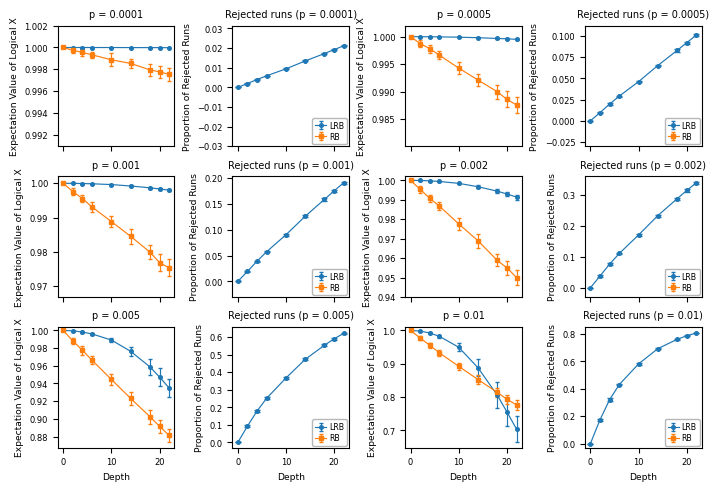

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== single_sd6


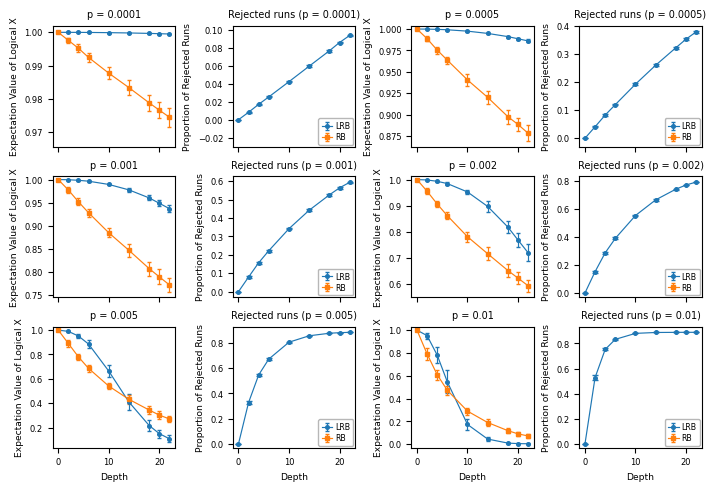

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== split_si1000


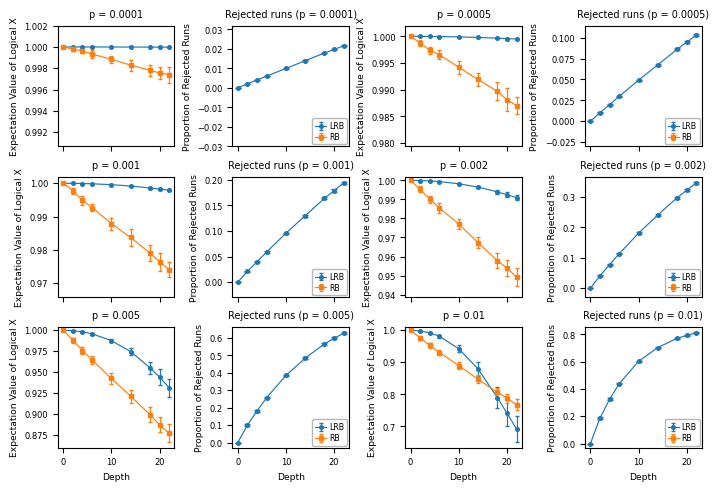

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== split_sd6


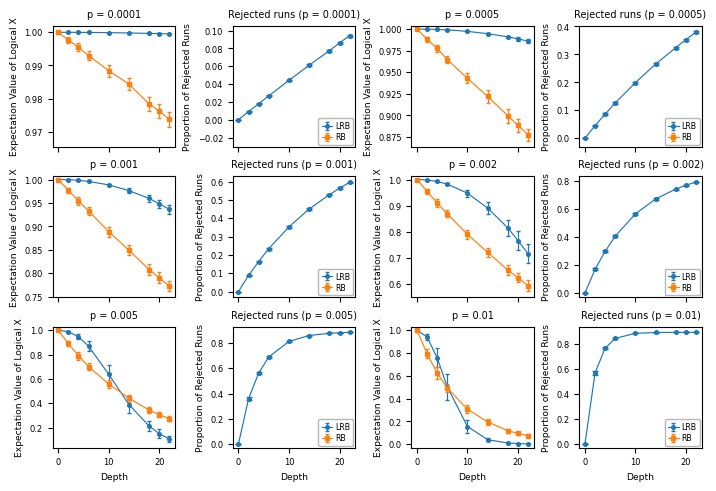

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf


{'single_si1000': ['/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'single_sd6': ['/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'split_si1000': ['/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'split_sd6': ['/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf']}

In [5]:
const_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    const_outputs[label] = plotter.plot_all_const_checks(
        show=True,
        check_min=0,
        check_max=0,
        paper_config=paper_plot_config,
    )
const_outputs

### 5. Uniform-check plots

Interval checks `1..4` for every run; raise `unif_plot_max` to `unif_check_max` for all intervals.

=== single_si1000


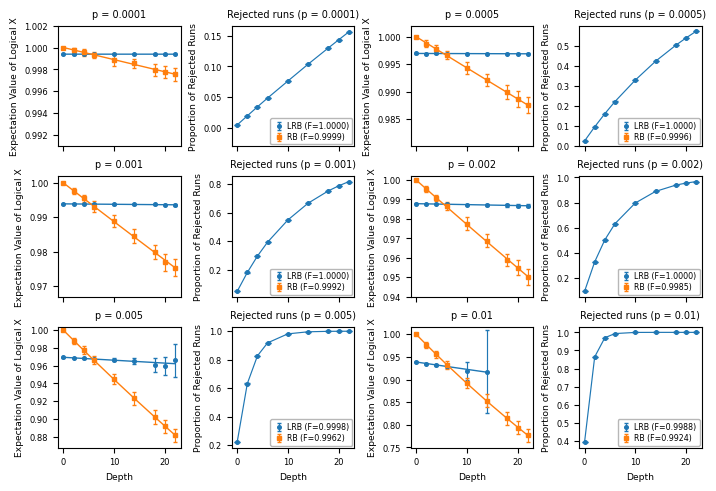

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


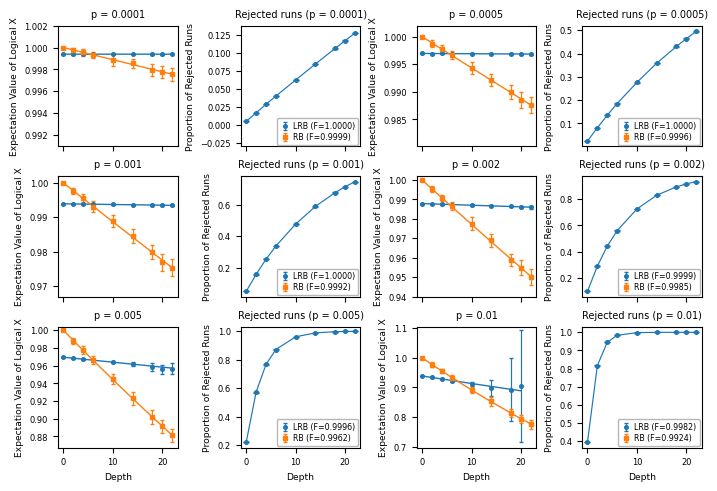

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


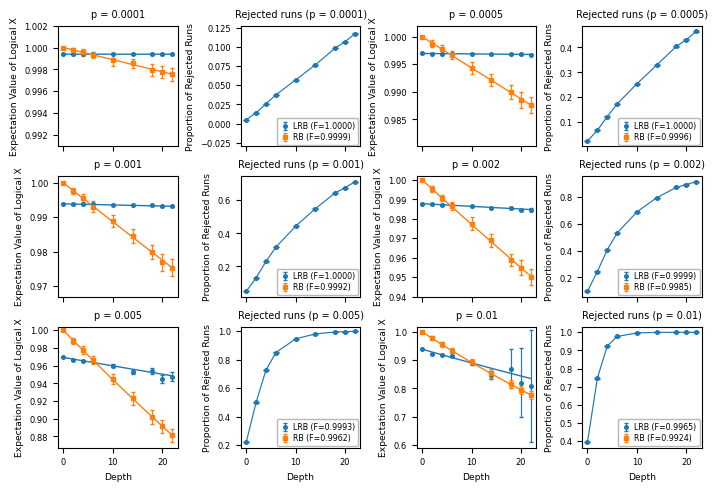

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


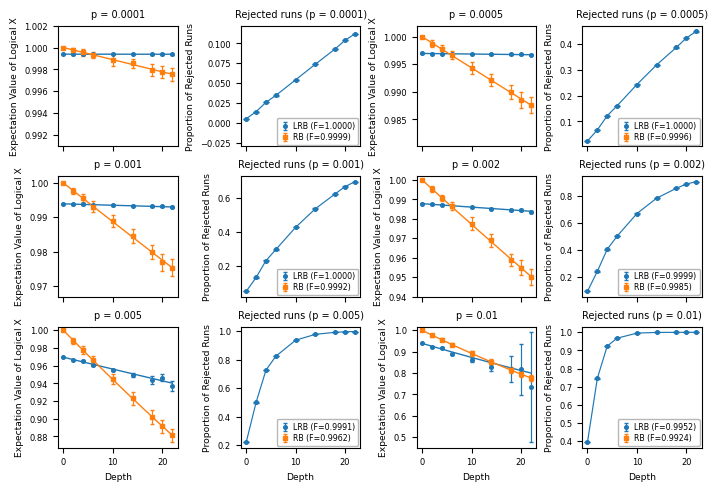

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== single_sd6


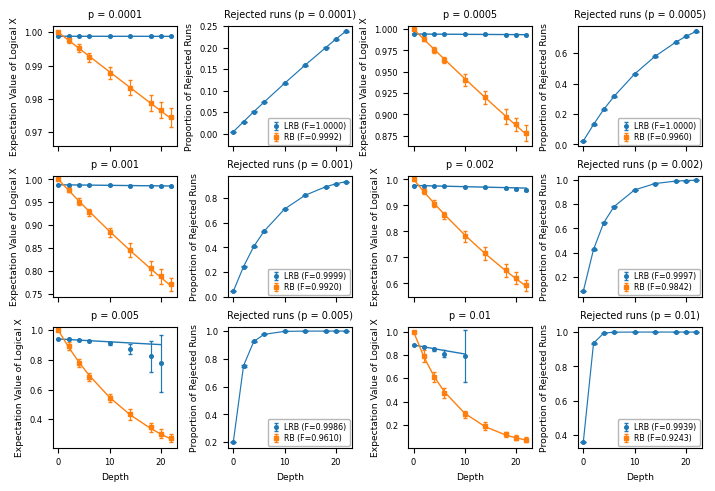

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


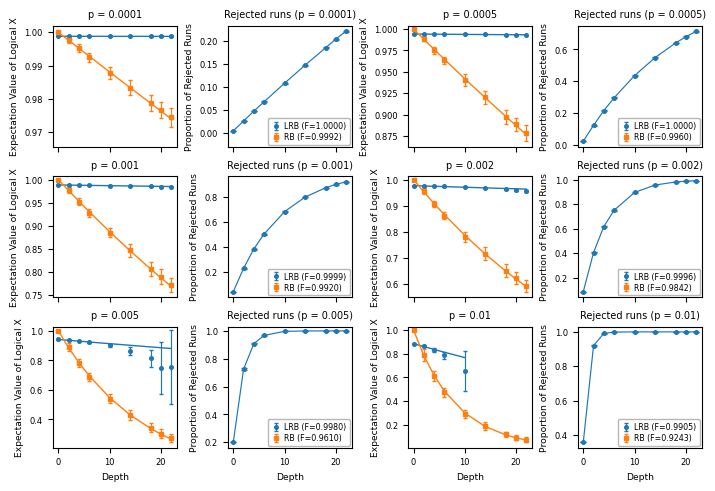

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


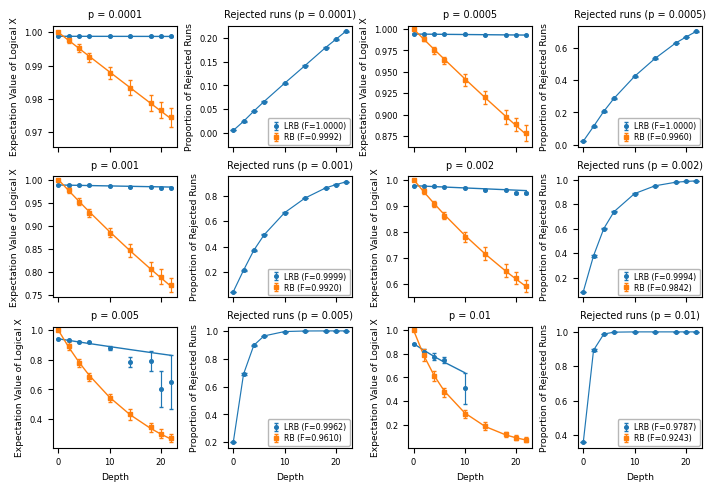

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


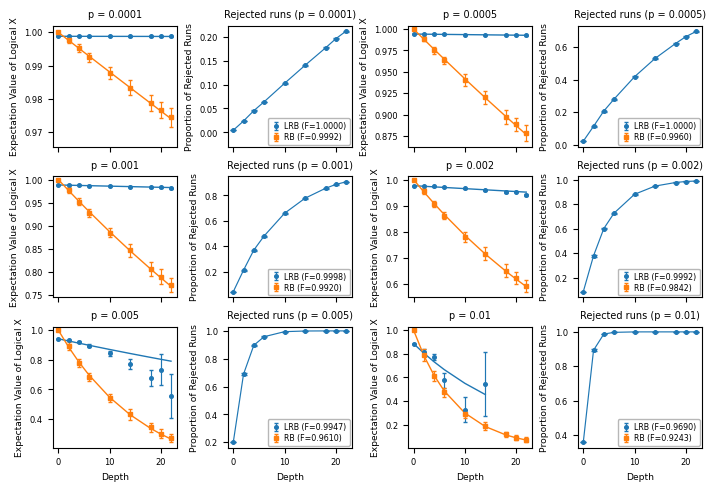

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== split_si1000


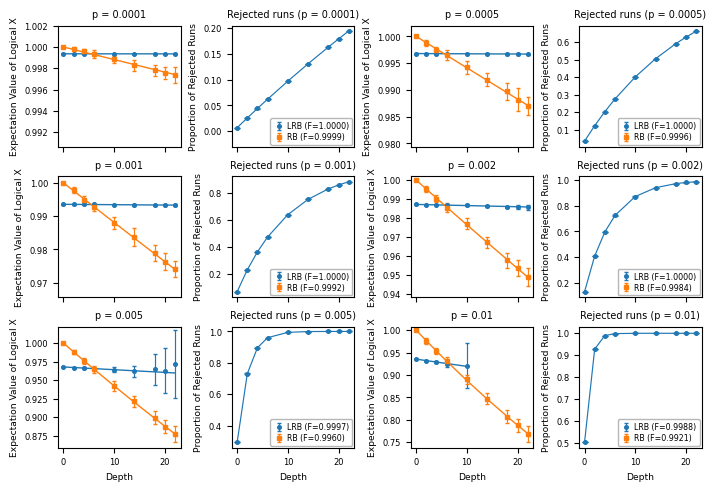

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


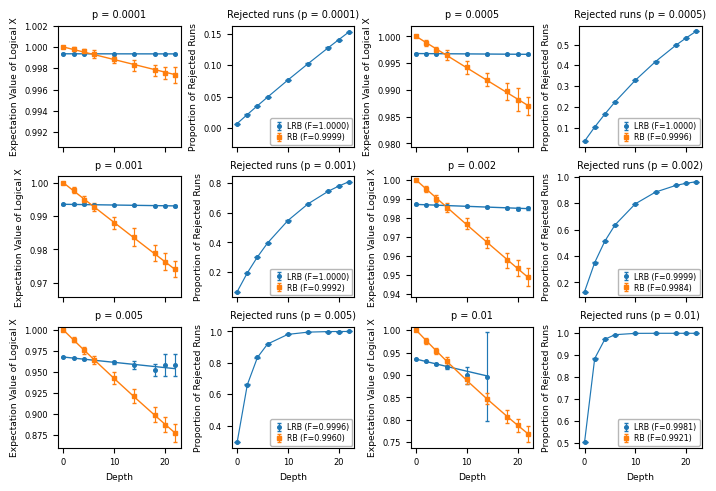

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


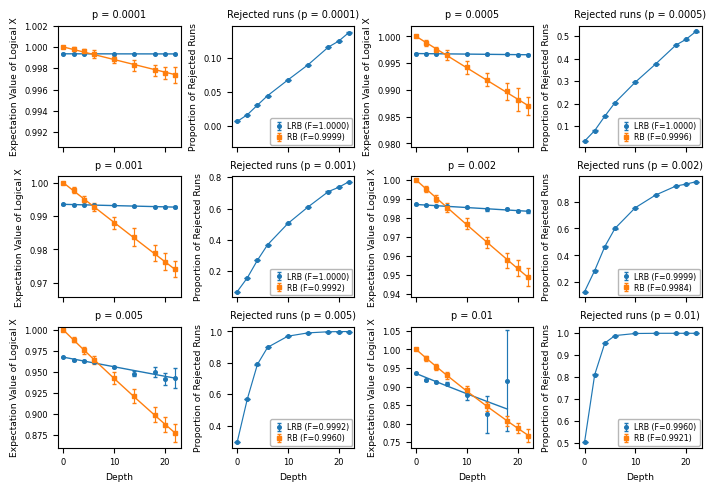

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


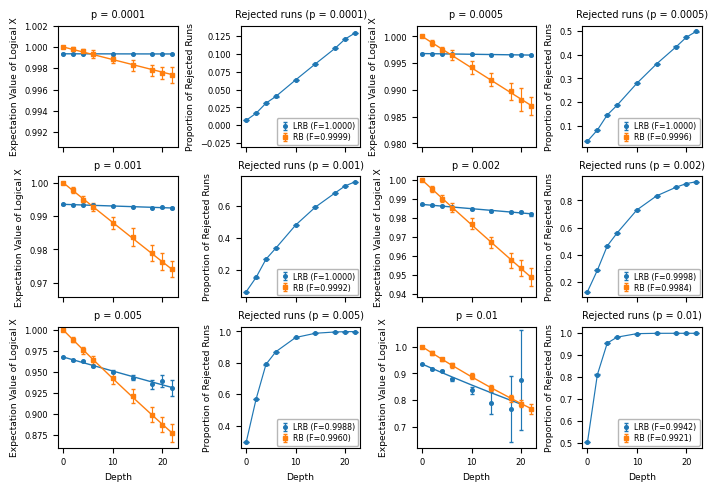

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== split_sd6


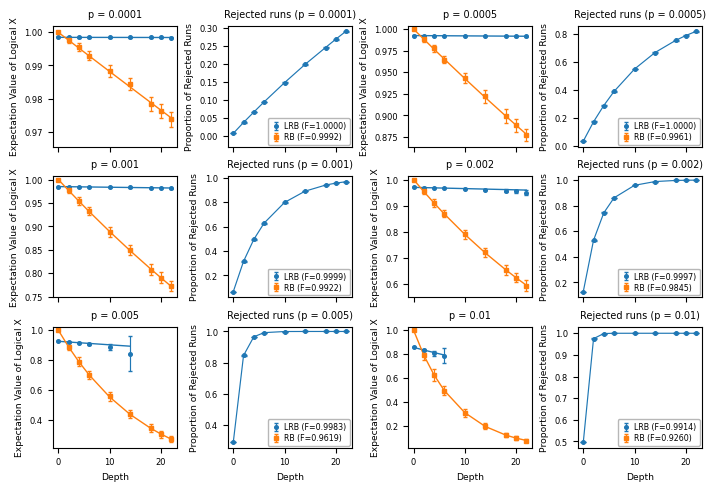

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


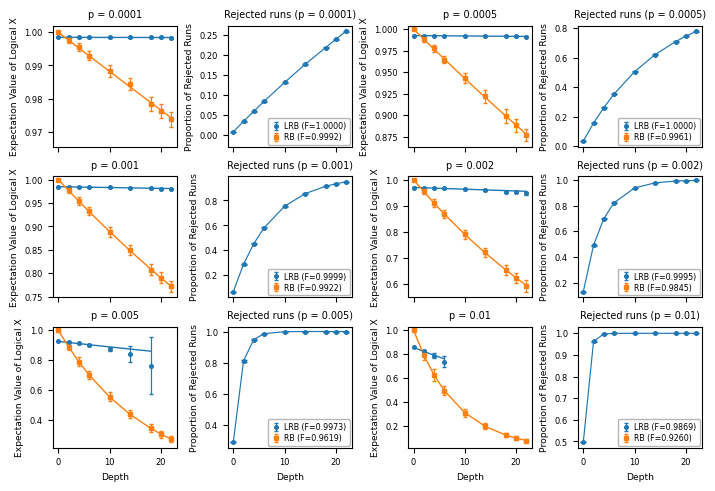

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


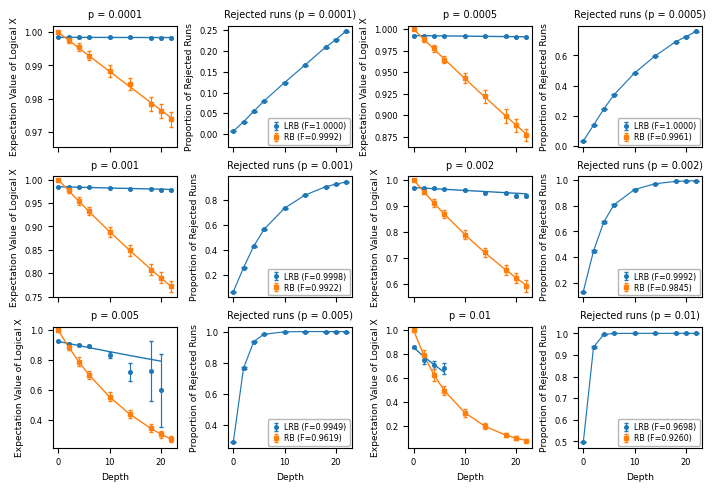

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


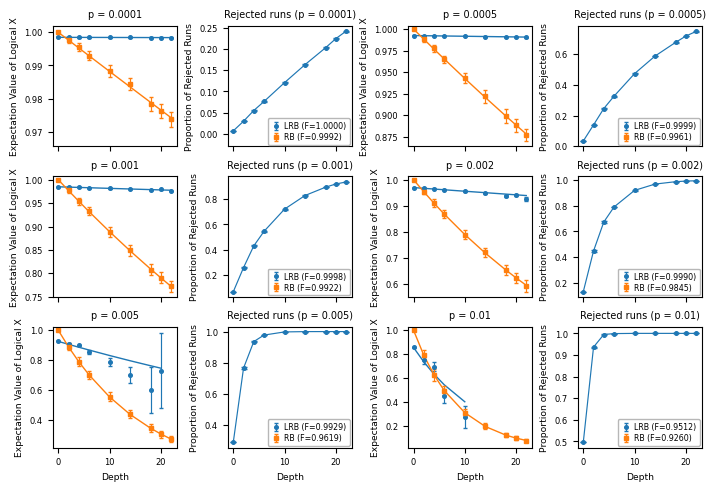

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf


{'single_si1000': ['/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf'],
 'single_sd6': ['/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/LRB-Simul

In [6]:
unif_plot_min, unif_plot_max = 1, 4
unif_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    unif_outputs[label] = plotter.plot_all_unif_checks(
        show=True,
        check_min=unif_plot_min,
        check_max=unif_plot_max,
        paper_config=paper_plot_config,
    )
unif_outputs

### 6. LRB-vs-RB tables and threshold summaries

LRB error rates and physical RB error rates are both placed at the same two-qudit gate error $p$. Uncertainties are bootstrap intervals as before.

=== single_si1000


[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-3-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-4-lrb-vs-rb-table-mix

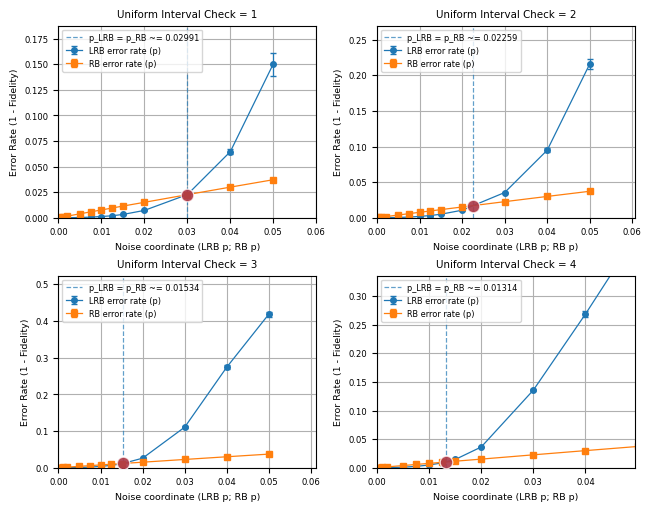

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0299108 +- 0.000675
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.022594 +- 0.000159
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.0153398 +- 7.77e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0131415 +- 5.56e-05
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[single_si1000] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,3.333333e-08,0.000000,2.010000e-07,0.000074,0.000073,0.000076,3.333333e-08,1.676667e-07,0.000001,0.000002
2,1,0.0002,0.0002,0.0002,0.0002,2.010000e-07,0.000000,4.355000e-07,0.000160,0.000158,0.000162,2.010000e-07,2.345000e-07,0.000002,0.000002
3,1,0.0005,0.0005,0.0005,0.0005,1.966785e-06,0.000002,2.432623e-06,0.000378,0.000374,0.000382,4.646250e-07,4.658376e-07,0.000004,0.000004
4,1,0.0010,0.0010,0.0010,0.0010,8.256750e-06,0.000007,8.985795e-06,0.000757,0.000751,0.000764,7.827500e-07,7.290450e-07,0.000007,0.000007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,1.008213e-01,0.100686,1.009728e-01,0.011377,0.011312,0.011442,1.350187e-04,1.514667e-04,0.000066,0.000064
326,22,0.0200,0.0200,0.0200,0.0200,1.484432e-01,0.148081,1.488107e-01,0.015052,0.014951,0.015141,3.623040e-04,3.675093e-04,0.000102,0.000089
327,22,0.0300,0.0300,0.0300,0.0300,2.753557e-01,0.274071,2.767397e-01,0.022536,0.022399,0.022663,1.284352e-03,1.383979e-03,0.000137,0.000127
328,22,0.0400,0.0400,0.0400,0.0400,3.852901e-01,0.382630,3.878994e-01,0.029894,0.029731,0.030052,2.659733e-03,2.609301e-03,0.000163,0.000158


[single_si1000] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.029911,0.000675,0.028831,0.030224,0.001080,0.000313
1,2,0.022594,0.000159,0.022428,0.022752,0.000166,0.000158
2,3,0.015340,0.000078,0.015275,0.015399,0.000065,0.000059
3,4,0.013141,0.000056,0.013087,0.013198,0.000055,0.000057


=== single_sd6


[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-3-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-4-lrb-vs-rb-table-mixed-fits.csv
[OK

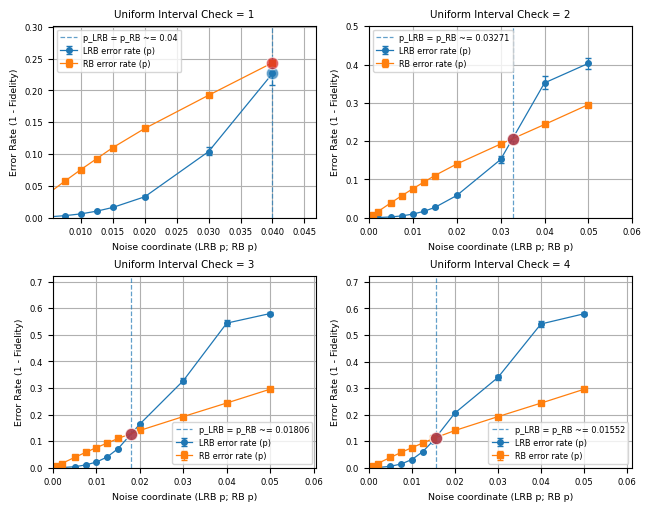

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.04 +- 0.000447
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0327067 +- 0.000583
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.0180629 +- 0.000324
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0155235 +- 0.000161
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[single_sd6] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000e+00,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,7.406667e-07,5.386667e-07,9.811667e-07,0.000796,0.000789,0.000803,2.020000e-07,2.405000e-07,0.000007,0.000007
2,1,0.0002,0.0002,0.0002,0.0002,3.341625e-06,3.010645e-06,3.746305e-06,0.001596,0.001583,0.001608,3.309800e-07,4.046800e-07,0.000013,0.000012
3,1,0.0005,0.0005,0.0005,0.0005,2.206003e-05,2.133513e-05,2.278053e-05,0.003982,0.003956,0.004008,7.248998e-07,7.204945e-07,0.000026,0.000026
4,1,0.0010,0.0010,0.0010,0.0010,8.256750e-05,8.084309e-05,8.442262e-05,0.007955,0.007903,0.008007,1.724407e-06,1.855125e-06,0.000052,0.000052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,2.523755e-01,2.501840e-01,2.542543e-01,0.110190,0.109497,0.110895,2.191509e-03,1.878869e-03,0.000693,0.000705
326,22,0.0200,0.0200,0.0200,0.0200,3.484651e-01,3.453349e-01,3.519961e-01,0.140265,0.139101,0.141266,3.130155e-03,3.531051e-03,0.001164,0.001001
327,22,0.0300,0.0300,0.0300,0.0300,4.413109e-01,4.376903e-01,4.455189e-01,0.192428,0.190540,0.194176,3.620672e-03,4.207979e-03,0.001887,0.001749
328,22,0.0400,0.0400,0.0400,0.0400,5.067664e-01,4.934867e-01,5.207883e-01,0.243421,0.240229,0.246455,1.327972e-02,1.402195e-02,0.003192,0.003033


[single_sd6] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.040000,0.000447,0.039796,0.040000,0.000204,0.000000
1,2,0.032707,0.000583,0.032133,0.033288,0.000573,0.000582
2,3,0.018063,0.000324,0.017785,0.018408,0.000278,0.000345
3,4,0.015524,0.000161,0.015359,0.015683,0.000164,0.000159


=== split_si1000


[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-3-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si100

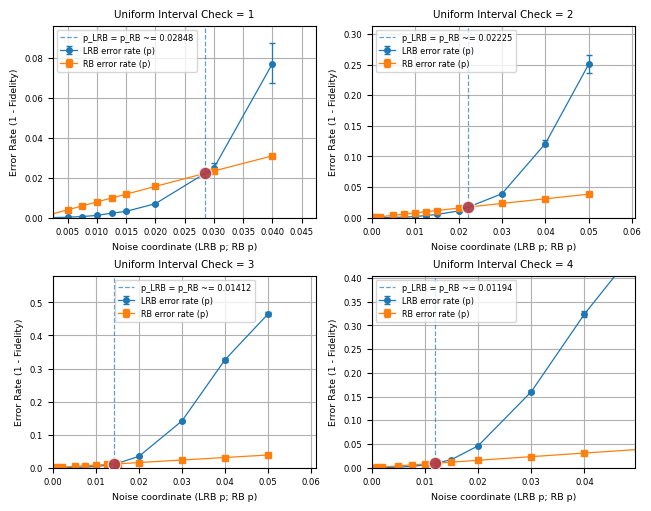

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0284836 +- 0.00153
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0222493 +- 0.000239
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.014122 +- 0.000105
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0119394 +- 0.000109
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[split_si1000] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000e+00,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,2.010000e-07,3.333333e-08,3.685000e-07,0.000079,0.000077,0.000080,1.676667e-07,1.675000e-07,0.000002,0.000001
2,1,0.0002,0.0002,0.0002,0.0002,4.020000e-07,1.675000e-07,6.060000e-07,0.000162,0.000159,0.000164,2.345000e-07,2.040000e-07,0.000003,0.000002
3,1,0.0005,0.0005,0.0005,0.0005,2.905622e-06,2.352182e-06,3.447150e-06,0.000393,0.000388,0.000398,5.534401e-07,5.415275e-07,0.000005,0.000005
4,1,0.0010,0.0010,0.0010,0.0010,7.361890e-06,6.414510e-06,8.256750e-06,0.000798,0.000791,0.000805,9.473800e-07,8.948600e-07,0.000007,0.000007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,1.121776e-01,1.119902e-01,1.123804e-01,0.011757,0.011683,0.011827,1.873707e-04,2.028373e-04,0.000073,0.000071
326,22,0.0200,0.0200,0.0200,0.0200,1.690336e-01,1.684878e-01,1.695163e-01,0.015648,0.015541,0.015746,5.457707e-04,4.827307e-04,0.000107,0.000098
327,22,0.0300,0.0300,0.0300,0.0300,2.839909e-01,2.821487e-01,2.855353e-01,0.023346,0.023196,0.023469,1.842219e-03,1.544384e-03,0.000149,0.000123
328,22,0.0400,0.0400,0.0400,0.0400,3.819493e-01,3.785226e-01,3.856140e-01,0.030895,0.030704,0.031079,3.426752e-03,3.664661e-03,0.000191,0.000184


[split_si1000] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.028484,0.001534,0.026760,0.030248,0.001724,0.001764
1,2,0.022249,0.000239,0.022021,0.022493,0.000229,0.000243
2,3,0.014122,0.000105,0.014023,0.014231,0.000099,0.000109
3,4,0.011939,0.000109,0.011839,0.012055,0.000100,0.000116


=== split_sd6


[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-3-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/resul

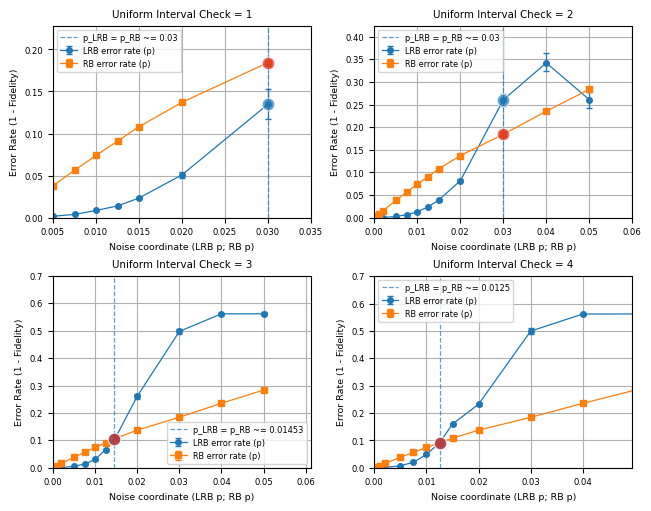

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.03 +- 3.7e-05
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.03 +- 0.00173
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.0145282 +- 0.000282
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0125 +- 0.000136
[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[split_sd6] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000,0.000000,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,0.000001,0.000001,1.751212e-06,0.000791,0.000785,0.000797,2.720000e-07,2.892125e-07,0.000006,0.000006
2,1,0.0002,0.0002,0.0002,0.0002,0.000004,0.000004,4.495365e-06,0.001556,0.001544,0.001566,3.726875e-07,4.117150e-07,0.000011,0.000010
3,1,0.0005,0.0005,0.0005,0.0005,0.000023,0.000022,2.434009e-05,0.003924,0.003900,0.003948,1.085943e-06,1.011050e-06,0.000024,0.000024
4,1,0.0010,0.0010,0.0010,0.0010,0.000093,0.000091,9.542218e-05,0.007790,0.007747,0.007829,2.251608e-06,2.314200e-06,0.000043,0.000039
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,0.300910,0.298501,3.036811e-01,0.108135,0.107525,0.108735,2.408747e-03,2.771285e-03,0.000610,0.000600
326,22,0.0200,0.0200,0.0200,0.0200,0.384334,0.380579,3.885524e-01,0.137140,0.136177,0.138024,3.755200e-03,4.218560e-03,0.000964,0.000884
327,22,0.0300,0.0300,0.0300,0.0300,0.462498,0.454156,4.702224e-01,0.184280,0.182492,0.186053,8.341141e-03,7.724843e-03,0.001788,0.001773
328,22,0.0400,0.0400,0.0400,0.0400,0.559092,0.554404,5.645076e-01,0.235245,0.232105,0.238239,4.687616e-03,5.415915e-03,0.003140,0.002994


[split_sd6] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.030000,0.000037,0.030000,0.03000,0.000000,0.000000
1,2,0.030000,0.001734,0.030000,0.03000,0.000000,0.000000
2,3,0.014528,0.000282,0.014269,0.01486,0.000260,0.000332
3,4,0.012500,0.000136,0.012331,0.01260,0.000169,0.000100


In [7]:
point_ci_columns = [
    "lrb_error_rate_std_boot",
    "lrb_error_rate_ci_low",
    "lrb_error_rate_ci_high",
    "rb_error_rate_std_boot",
    "rb_error_rate_ci_low",
    "rb_error_rate_ci_high",
]
force_rebuild_uncertainty_table = False


def table_has_point_uncertainty(path: Path) -> bool:
    if not path.exists():
        return False
    columns = pd.read_csv(path, nrows=0).columns
    return all(col in columns for col in point_ci_columns)


table_csvs, summary_csvs, uncertainty_tables, pseudo_threshold_tables = {}, {}, {}, {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    table_csv_path = Path(plotter.out_dir) / "unif_lrb_vs_rb_table_all_mixed_fits.csv"
    if force_rebuild_uncertainty_table or not table_has_point_uncertainty(table_csv_path):
        table_csvs[label] = plotter.build_unif_lrb_vs_rb_table_mixed_fits(
            write_per_check_tables=True,
            check_min=unif_check_min,
            check_max=unif_check_max,
            bootstrap_reps=threshold_config.bootstrap_reps_error,
            bootstrap_ci_level=threshold_config.bootstrap_ci_level,
            bootstrap_use_sem=threshold_config.bootstrap_use_sem,
            bootstrap_seed=threshold_config.bootstrap_seed,
        )
    else:
        table_csvs[label] = str(table_csv_path)
    summary_csvs[label] = plotter.plot_all_unif_threshold_graphs(
        threshold_config=threshold_config,
        table_csv_path=table_csvs[label],
        show=True,
        check_min=unif_check_min,
        check_max=4,
    )
    uncertainty_tables[label] = show_error_rate_uncertainty_table(table_csvs[label], label=label)
    pseudo_threshold_tables[label] = show_pseudo_threshold_uncertainty_table(
        summary_csvs[label],
        label=label,
        check_min=unif_check_min,
        check_max=unif_check_max,
    )

### 7. Pseudo-threshold trend vs interval check

The focused `1..4` pseudo-threshold trend for every run.

[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0299108 +- 0.000675
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.022594 +- 0.000159
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.0153398 +- 7.77e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0131415 +- 5.56e-05
[FIT] fit disabled by do_fit=False.


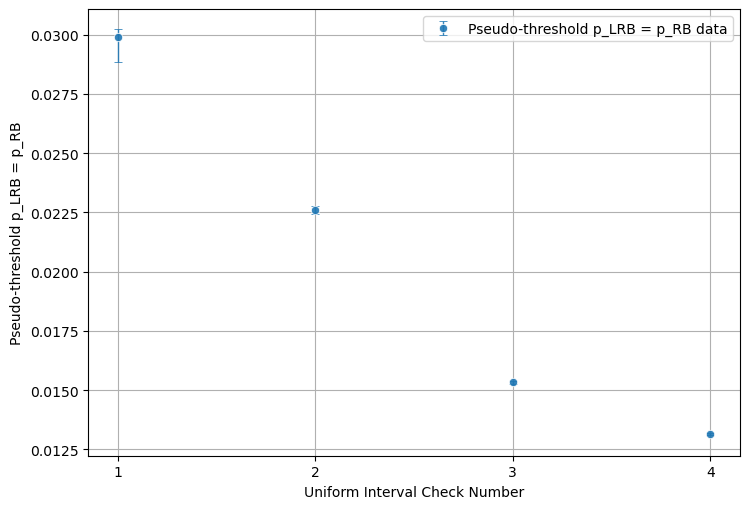

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.04 +- 0.000447
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0327067 +- 0.000583
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.0180629 +- 0.000324
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0155235 +- 0.000161
[FIT] fit disabled by do_fit=False.


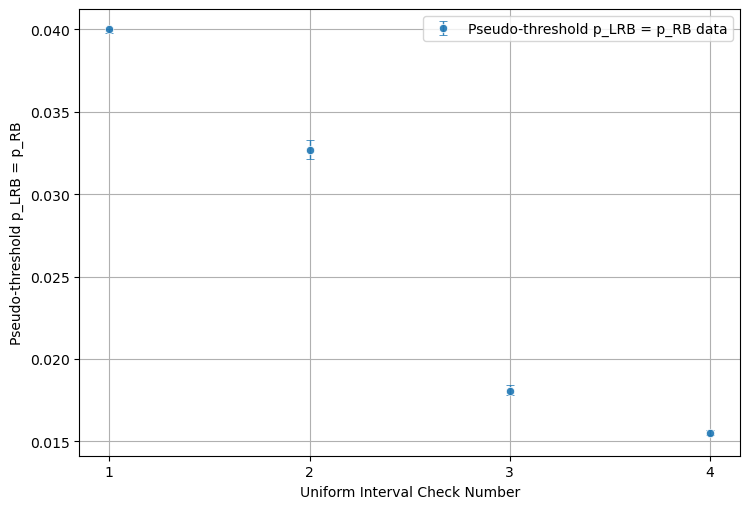

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0284836 +- 0.00153
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0222493 +- 0.000239
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.014122 +- 0.000105
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0119394 +- 0.000109
[FIT] fit disabled by do_fit=False.


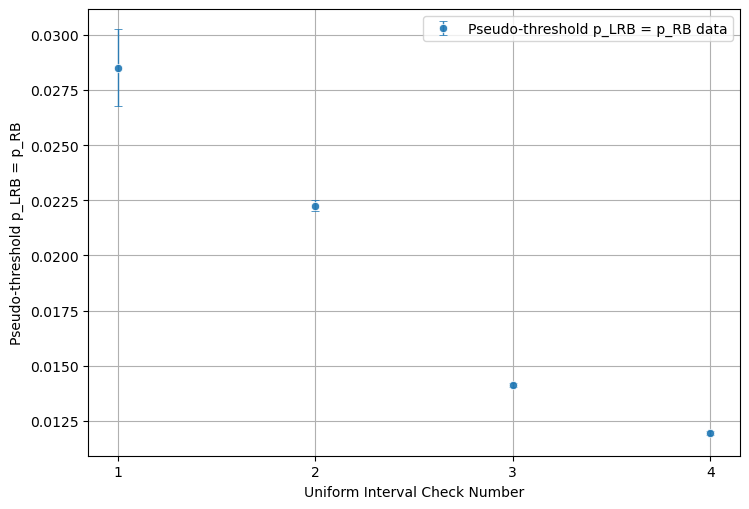

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.03 +- 3.7e-05
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.03 +- 0.00173
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.0145282 +- 0.000282
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0125 +- 0.000136
[FIT] fit disabled by do_fit=False.


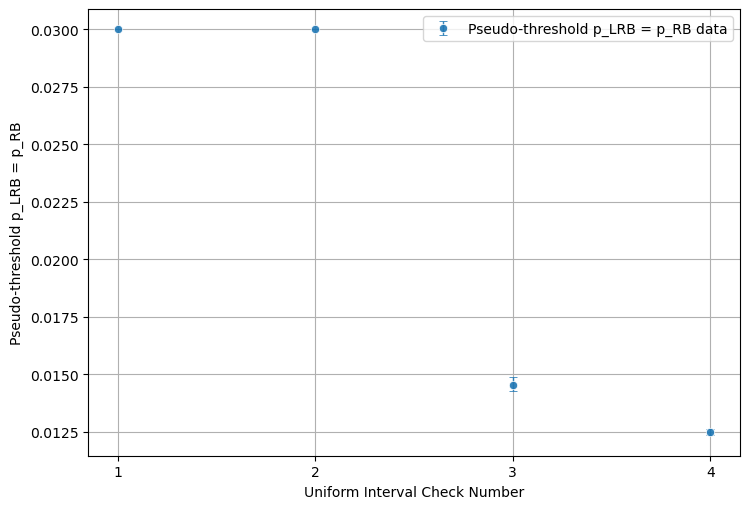

[OK] wrote /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf


{'single_si1000': '/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'single_sd6': '/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'split_si1000': '/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'split_sd6': '/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf'}

In [8]:
pseudo_pdfs = {}
for label, plotter in plotters.items():
    pseudo_pdfs[label] = plotter.plot_unif_pseudo_thresholds_vs_interval_check(
        check_min=unif_check_min,
        check_max=4,
        do_fit=pseudo_do_fit,
        fit_model=pseudo_fit_model,
        fit_degree=pseudo_fit_degree,
        paper_mode=paper_plot_config.enabled,
        show=True,
    )
pseudo_pdfs

### 8. Four-configuration comparison

Logical error per Clifford with a check after every Clifford (uniform interval 1) for all four runs, against physical single-qutrit RB under each noise model, versus the two-qudit gate error $p$. Points without a valid fit are omitted.

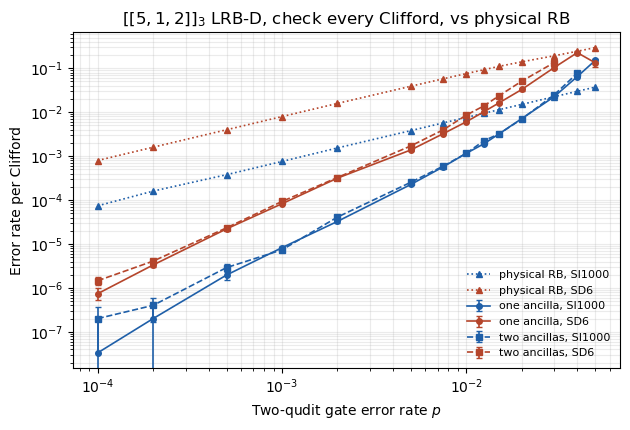

/pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/comparisons/sdim140-si1000-sd6/lrb-vs-rb-unif-1-four-configurations.pdf


In [9]:
import matplotlib.pyplot as plt
import numpy as np

comparison_dir = RUNS_ROOT / "comparisons" / "sdim140-si1000-sd6"
comparison_dir.mkdir(parents=True, exist_ok=True)
comparison_check = 1
styles = {
    "single_si1000": dict(color="#1f5fa8", marker="o", linestyle="-", label="one ancilla, SI1000"),
    "split_si1000": dict(color="#1f5fa8", marker="s", linestyle="--", label="two ancillas, SI1000"),
    "single_sd6": dict(color="#b5452b", marker="o", linestyle="-", label="one ancilla, SD6"),
    "split_sd6": dict(color="#b5452b", marker="s", linestyle="--", label="two ancillas, SD6"),
}
fig, ax = plt.subplots(figsize=(6.4, 4.4))
rows = []
for label, table_csv in table_csvs.items():
    frame = pd.read_csv(table_csv)
    frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
    lrb = frame[np.isfinite(frame["lrb_error_rate"]) & (frame["lrb_error_rate"] > 0)]
    yerr = np.vstack([
        lrb["lrb_error_rate"] - lrb["lrb_error_rate_ci_low"],
        lrb["lrb_error_rate_ci_high"] - lrb["lrb_error_rate"],
    ]).clip(min=0)
    ax.errorbar(lrb["p"], lrb["lrb_error_rate"], yerr=yerr, markersize=4, capsize=2, linewidth=1.2, **styles[label])
    rows.append(frame.assign(run=label))
for label, color in (("single_si1000", "#1f5fa8"), ("single_sd6", "#b5452b")):
    frame = pd.read_csv(table_csvs[label])
    frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
    rb = frame[np.isfinite(frame["rb_error_rate"]) & (frame["rb_error_rate"] > 0)]
    noise_title = "SI1000" if label.endswith("si1000") else "SD6"
    ax.plot(rb["p"], rb["rb_error_rate"], color=color, linestyle=":", marker="^", markersize=4,
            linewidth=1.2, label=f"physical RB, {noise_title}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(fit_config.p_axis_label)
ax.set_ylabel("Error rate per Clifford")
ax.set_title(r"$[[5,1,2]]_3$ LRB-D, check every Clifford, vs physical RB")
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
comparison_pdf = comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-four-configurations.pdf"
fig.savefig(comparison_pdf)
fig.savefig(comparison_pdf.with_suffix(".png"), dpi=160)
plt.show()
comparison_table = pd.concat(rows, ignore_index=True)[
    ["run", "p", "lrb_error_rate", "lrb_error_rate_ci_low", "lrb_error_rate_ci_high",
     "rb_error_rate", "rb_error_rate_ci_low", "rb_error_rate_ci_high"]
]
comparison_table.to_csv(comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-four-configurations.csv", index=False)
print(comparison_pdf)

### 9. GIF animations

The const=0 sweep over $p$ and the interval-check sweep at each $p$, per run. This is the slowest step, so it runs last; runs with a complete GIF set are reused.

single_si1000: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140/results/plots/gifs
single_sd6: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140/results/plots/gifs
split_si1000: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140/results/plots/gifs
split_sd6: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/LRB-Simulations-sdim/LRB-experiment-data-slurm/Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140/results/plots/gifs


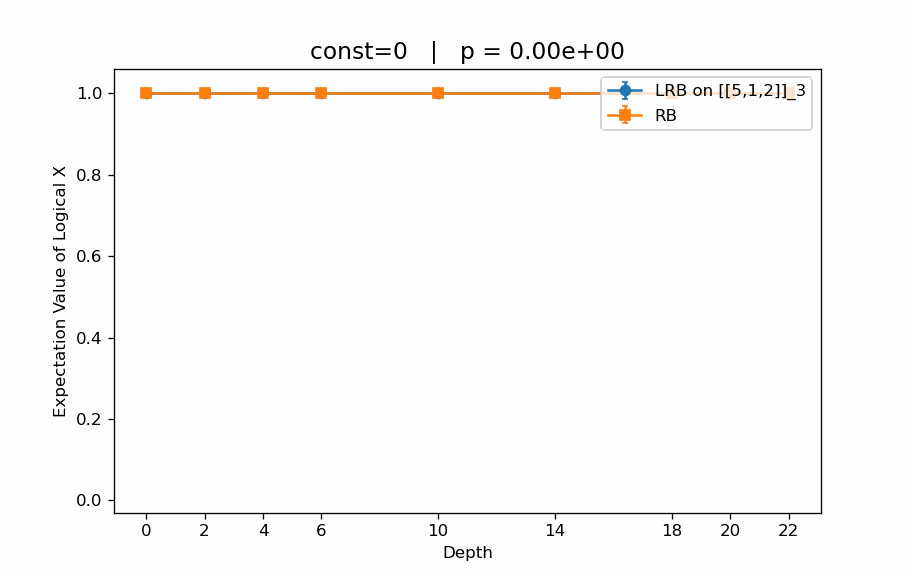

In [10]:
# GIFs are the slowest step. A run whose GIF set (the const=0 sweep plus one
# interval sweep per p) is already complete is reused; the rest are rebuilt.
gif_outputs = {}
for label, plotter in plotters.items():
    animator = LRBGifAnimator(plotter, render_config=gif_render_config)
    const_gif = animator.out_dir / "const-0-rb-lrb-vs-p.gif"
    interval_gifs = sorted(animator.out_dir.glob("unif-interval-sweep-pidx*.gif"))
    if const_gif.exists() and len(interval_gifs) == len(plotter.probabilities):
        const_gif, interval_gifs = str(const_gif), [str(path) for path in interval_gifs]
    else:
        const_gif = animator.create_const_sweep_gif(const_check=0, strict=True)
        interval_gifs = animator.create_unif_interval_gifs_for_all_probabilities(
            interval_min=unif_check_min,
            interval_max=unif_check_max,
            strict=True,
        )
    gif_outputs[label] = (const_gif, interval_gifs)
    print(f"{label}: {Path(const_gif).name} + {len(interval_gifs)} interval GIFs in {animator.out_dir}")
display(Image(filename=gif_outputs["single_si1000"][0]))

## 10. Reading guide

Per-run PDFs, tables and GIFs are under each run's `results/plots/`; the four-configuration comparison is under `LRB-experiment-data-slurm/comparisons/sdim140-si1000-sd6/`. In every figure the horizontal axis is the two-qudit gate depolarizing probability $p$. SI1000 sets one-qudit gates to $p/10$, measurement flips to $5p$, reset flips and resonator idles to $2p$, and idles to $p/10$. SD6 sets every operation, idles included, to $p$. Physical RB at a given $p$ uses only one-qudit gates, so under SI1000 it sees $p/10$ per gate, and the LRB/RB pseudo-thresholds reflect that asymmetry.